##CRANK_NICOLSON METHOD FOR EXAMPLE 2

In [505]:
import numpy as np
import matplotlib.pyplot as plt

### Crank–Nicolson Method for Example 2

We consider the equation

$$
u_t = c_d u_{xx} + c_s u(1-u)(u-a)
$$

with

$$
c_d = 1, \quad c_s = 1, \quad a = 0.5
$$

Initial condition:

$$
u(x,0) = e^{-(x+1)}, \quad -1 \leq x \leq 1
$$

Neumann boundary conditions:

$$
u_x(-1,t) = -1
$$

$$
u_x(1,t) = -e^{-2}
$$

Final time:

$$
T = 0.5
$$

In [506]:
# Parameters for Example 2

x_left = -1
x_right = 1

T = 0.5

Nx = 20
Nt = 100

c_d = 1
c_s = 50
a = 0.5

dx = (x_right - x_left) / Nx
dt = T / Nt

x = np.linspace(x_left, x_right, Nx + 1)
t = np.linspace(0, T, Nt + 1)

print("Parameters set.")
print("dx =", dx)
print("dt =", dt)

Parameters set.
dx = 0.1
dt = 0.005


In [507]:
# Initial condition

u = np.exp(-(x + 1))

In [508]:
def reaction(u, c_s, a):
    return c_s * u * (1 - u) * (u - a)

In [509]:
r = c_d * dt / (2 * dx**2)

print("r =", r)


r = 0.24999999999999994


In [510]:
# Neumann boundary condition values

g_left = -1
g_right = -np.exp(-2)

print("g_left =", g_left)
print("g_right =", g_right)

g_left = -1
g_right = -0.1353352832366127


### Crank–Nicolson Matrix for Example 2

For the diffusion term, we use the Crank–Nicolson discretisation

$$
\frac{u_i^{n+1}-u_i^n}{\Delta t}
=
\frac{c_d}{2}
\left[
\frac{u_{i+1}^{n+1}-2u_i^{n+1}+u_{i-1}^{n+1}}{\Delta x^2}
+
\frac{u_{i+1}^{n}-2u_i^{n}+u_{i-1}^{n}}{\Delta x^2}
\right]
+
c_su_i^n(1-u_i^n)(u_i^n-a).
$$

Let

$$
r=\frac{c_d\Delta t}{2\Delta x^2}.
$$

For the interior points, the terms involving the new time level are

$$
-r u_{i-1}^{n+1}
+
(1+2r)u_i^{n+1}
-r u_{i+1}^{n+1}.
$$

Therefore, the matrix $A$ has the tridiagonal form

$$
A=
\begin{bmatrix}
1+2r & -2r & 0 & \cdots & 0\\
-r & 1+2r & -r & \cdots & 0\\
0 & -r & 1+2r & \ddots & \vdots\\
\vdots & \ddots & \ddots & \ddots & -r\\
0 & \cdots & 0 & -2r & 1+2r
\end{bmatrix}.
$$

The first and last rows are modified because Example 2 has Neumann boundary conditions.

At the left boundary,

$$
u_x(-1,t)=-1,
$$

and at the right boundary,

$$
u_x(1,t)=-e^{-2}.
$$

Using ghost points gives

$$
u_{-1}=u_1+2\Delta x
$$

and

$$
u_{N+1}=u_{N-1}-2\Delta x e^{-2}.
$$

These conditions modify the coefficients in the first and last rows of $A$.

In [511]:
# Crank-Nicolson matrix A

N = Nx + 1

A = np.zeros((N, N))

# Interior points
for i in range(1, N - 1):
    A[i, i - 1] = -r
    A[i, i] = 1 + 2*r
    A[i, i + 1] = -r

# Left boundary
A[0, 0] = 1 + 2*r
A[0, 1] = -2*r

# Right boundary
A[-1, -2] = -2*r
A[-1, -1] = 1 + 2*r



### Crank–Nicolson Matrix $B$


For the interior points, the terms at time level $n$ are

$$
r u_{i-1}^{n}
+
(1-2r)u_i^n
+
r u_{i+1}^{n}.
$$

Therefore, the interior rows of $B$ contain

$$
r,\quad 1-2r,\quad r.
$$

Using the Neumann boundary conditions and the ghost-point relations, the boundary rows are modified.

The resulting matrix is

$$
B=
\begin{bmatrix}
1-2r & 2r & 0 & \cdots & 0\\
r & 1-2r & r & \cdots & 0\\
0 & r & 1-2r & \ddots & \vdots\\
\vdots & \ddots & \ddots & \ddots & r\\
0 & \cdots & 0 & 2r & 1-2r
\end{bmatrix}.
$$

The constant terms produced by the Neumann boundary conditions are then added separately to the right-hand side.

In [512]:
# Correct Crank-Nicolson matrix B

B = np.zeros((N, N))

# Left boundary
B[0, 0] = 1 - 2*r
B[0, 1] = 2*r

# Interior points
for i in range(1, N - 1):
    B[i, i - 1] = r
    B[i, i] = 1 - 2*r
    B[i, i + 1] = r

# Right boundary
B[-1, -2] = 2*r
B[-1, -1] = 1 - 2*r


In [513]:
# Store the solution at all time steps

U_CN = np.zeros((Nt + 1, Nx + 1))

U_CN[0, :] = u



In [514]:
# Crank-Nicolson time-stepping

u = np.exp(-(x + 1))

U_CN = np.zeros((Nt + 1, Nx + 1))
U_CN[0, :] = u

for n in range(Nt):

    # Reaction term at the current time level
    reaction_term = dt * reaction(u, c_s, a)

    # Right-hand side
    rhs = B @ u + reaction_term

    # Neumann boundary contributions
    rhs[0] += -4 * r * dx * g_left
    rhs[-1] += 4 * r * dx * g_right

    # Solve for the new time level
    u_new = np.linalg.solve(A, rhs)

    # Update solution
    u = u_new.copy()

    # Store solution
    U_CN[n + 1, :] = u

In [515]:
print("Minimum value:", np.min(U_CN))
print("Maximum value:", np.max(U_CN))
print("Final-time minimum:", np.min(U_CN[-1, :]))
print("Final-time maximum:", np.max(U_CN[-1, :]))

Minimum value: -0.02111442813128983
Maximum value: 1.1444485907839812
Final-time minimum: -0.02078468819536808
Final-time maximum: 1.1444485907839812


### Treatment of the Neumann Boundary Conditions

For the left boundary,

$$
u_x(-1,t)=-1.
$$

Using a second-order central difference with a ghost point gives

$$
\frac{u_1-u_{-1}}{2\Delta x}=-1,
$$

so that

$$
u_{-1}=u_1+2\Delta x.
$$

Therefore,

$$
u_{xx}(-1,t)
\approx
\frac{u_1-2u_0+u_{-1}}{\Delta x^2}
$$

and hence

$$
u_{xx}(-1,t)
\approx
\frac{2u_1-2u_0+2\Delta x}{\Delta x^2}.
$$

Similarly, at the right boundary,

$$
u_x(1,t)=-e^{-2}.
$$

Using a ghost point,

$$
\frac{u_{N+1}-u_{N-1}}{2\Delta x}
=
-e^{-2},
$$

which gives

$$
u_{N+1}
=
u_{N-1}-2\Delta x e^{-2}.
$$

Therefore,

$$
u_{xx}(1,t)
\approx
\frac{2u_{N-1}-2u_N-2\Delta x e^{-2}}
{\Delta x^2}.
$$

These expressions are substituted into the Crank–Nicolson scheme at the two boundary points. This allows the Neumann conditions to be incorporated directly into the linear system.

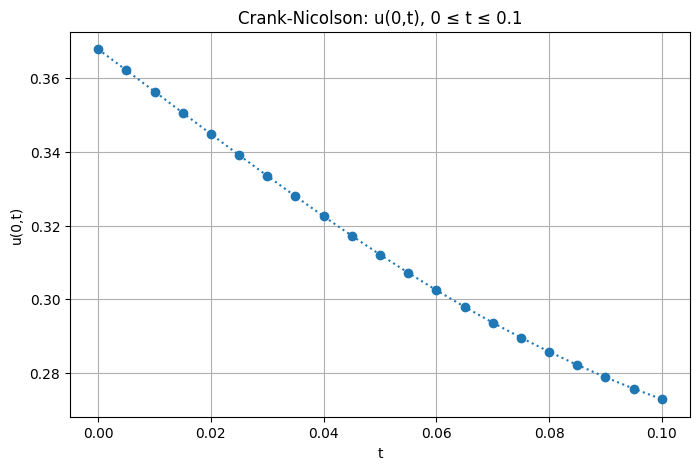

In [516]:
# Plot u(0,t) for 0 <= t <= 0.1

x0_index = np.argmin(np.abs(x - 0))
mask = t <= 0.1

plt.figure(figsize=(8, 5))
plt.plot(t[mask], U_CN[mask, x0_index], marker ='o',linestyle=':')
plt.xlabel("t")
plt.ylabel("u(0,t)")
plt.title("Crank-Nicolson: u(0,t), 0 ≤ t ≤ 0.1")
plt.grid()
plt.show()

In [517]:
print("x at index:", x[x0_index])
print("u(0,0):", U_CN[0, x0_index])
print("u(0,0.1):", U_CN[np.argmin(np.abs(t - 0.1)), x0_index])
print("u(0,0.5):", U_CN[-1, x0_index])

x at index: 0.0
u(0,0): 0.36787944117144233
u(0,0.1): 0.27287110358336797
u(0,0.5): 0.2858860643996957


In [518]:
print("Nx =", Nx)
print("Nt =", Nt)
print("dx =", dx)
print("dt =", dt)

print("u(0,0):", U_CN[0, x0_index])
print("u(0,0.1):", U_CN[np.argmin(np.abs(t - 0.1)), x0_index])
print("u(0,0.5):", U_CN[-1, x0_index])

Nx = 20
Nt = 100
dx = 0.1
dt = 0.005
u(0,0): 0.36787944117144233
u(0,0.1): 0.27287110358336797
u(0,0.5): 0.2858860643996957


In [519]:
def reference_solution(Nx_ref=1600, T=0.5, t_eval=None):

    xr = np.linspace(-1, 1, Nx_ref + 1)
    dxr = xr[1] - xr[0]

    def full(ui):
        u = np.empty(Nx_ref + 1)

        u[1:-1] = ui

        u[0] = (4 * u[1] - u[2] - 2 * dxr * g_left) / 3
        u[-1] = (4 * u[-2] - u[-3] + 2 * dxr * g_right) / 3

        return u

    def rhs(t, ui):

        u = full(ui)

        uxx = (
            u[2:] - 2 * u[1:-1] + u[:-2]
        ) / dxr**2

        return c_d * uxx + reaction(u[1:-1], c_s, a)

    sol = solve_ivp(
        rhs,
        [0, T],
        np.exp(-(xr + 1))[1:-1],
        method="BDF",
        rtol=1e-9,
        atol=1e-11,
        t_eval=t_eval
    )

    return xr, sol

In [520]:
xr_ref, sol_ref = reference_solution(
    Nx_ref=1600,
    T=0.5,
    t_eval=[0.5]
)

u_ref = np.empty(len(xr_ref))

u_ref[1:-1] = sol_ref.y[:, -1]

dxr = xr_ref[1] - xr_ref[0]

u_ref[0] = (4 * u_ref[1] - u_ref[2] - 2 * dxr * g_left) / 3
u_ref[-1] = (4 * u_ref[-2] - u_ref[-3] + 2 * dxr * g_right) / 3

print("Reference solution computed at t = 0.5")
print("Reference grid points:", len(xr_ref))
print("dx_ref =", dxr)

Reference solution computed at t = 0.5
Reference grid points: 1601
dx_ref = 0.0012499999999999734


In [521]:
# Maximum absolute error at t = 0.5

u_ref_on_CN = np.interp(x, xr_ref, u_ref)

error = np.abs(U_CN[-1, :] - u_ref_on_CN)

max_error = np.max(error)

print("Maximum absolute error =", max_error)

Maximum absolute error = 0.008652530757468746


In [522]:
def solve_cn(Nx=20, Nt=100, T=0.5):

    x = np.linspace(-1, 1, Nx + 1)
    dx = x[1] - x[0]
    dt = T / Nt
    r = c_d * dt / (2 * dx**2)

    N = Nx + 1

    # Matrix A
    A = np.zeros((N, N))

    for i in range(1, N - 1):
        A[i, i - 1] = -r
        A[i, i] = 1 + 2 * r
        A[i, i + 1] = -r

    A[0, 0] = 1 + 2 * r
    A[0, 1] = -2 * r

    A[-1, -2] = -2 * r
    A[-1, -1] = 1 + 2 * r

    # Matrix B
    B = np.zeros((N, N))

    for i in range(1, N - 1):
        B[i, i - 1] = r
        B[i, i] = 1 - 2 * r
        B[i, i + 1] = r

    B[0, 0] = 1 - 2 * r
    B[0, 1] = 2 * r

    B[-1, -2] = 2 * r
    B[-1, -1] = 1 - 2 * r

    # Initial condition
    u = np.exp(-(x + 1))

    U = np.zeros((Nt + 1, N))
    U[0, :] = u

    # Time stepping
    for n in range(Nt):

        reaction_term = dt * reaction(u, c_s, a)

        rhs = B @ u + reaction_term

        # Corrected Neumann boundary contributions
        rhs[0] += -4 * r * dx * g_left
        rhs[-1] += 4 * r * dx * g_right

        u = np.linalg.solve(A, rhs)

        U[n + 1, :] = u

    t = np.linspace(0, T, Nt + 1)

    return x, t, U, dx, dt, r

In [523]:
# Maximum absolute error for different spatial grids

Nx_values = [10, 20, 40, 80, 120]

errors = []

for Nx_test in Nx_values:

    # Keep the same relationship: dt ≈ 0.2 dx
    dx_test = 2.0 / Nx_test
    dt_target = 0.2 * dx_test

    Nt_test = int(np.ceil(0.5 / dt_target))

    # Solve CN
    x_test, t_test, U_test, dx_test, dt_test, r_test = solve_cn(
        Nx=Nx_test,
        Nt=Nt_test,
        T=0.5
    )

    # Interpolate reference solution onto CN grid
    u_ref_test = np.interp(x_test, xr_ref, u_ref)

    # Maximum absolute error at t = 0.5
    error_test = np.max(
        np.abs(U_test[-1, :] - u_ref_test)
    )

    errors.append(error_test)

    print(
        f"Nx = {Nx_test:3d}, "
        f"Nt = {Nt_test:4d}, "
        f"Max error = {error_test:.6e}"
    )

Nx =  10, Nt =   13, Max error = 2.742329e-02
Nx =  20, Nt =   25, Max error = 8.800590e-03
Nx =  40, Nt =   50, Max error = 3.403359e-03
Nx =  80, Nt =  100, Max error = 1.573061e-03
Nx = 120, Nt =  150, Max error = 1.024181e-03


In [524]:
# Compute observed convergence orders

Nx_values = np.array([10, 20, 40, 80, 120])
errors = np.array([
    2.742329e-02,
    8.800590e-03,
    3.403359e-03,
    1.573061e-03,
    1.024181e-03
])

dx_values = 2 / Nx_values

orders = []

for i in range(len(errors) - 1):
    p = np.log(errors[i] / errors[i + 1]) / np.log(dx_values[i] / dx_values[i + 1])
    orders.append(p)

for i, p in enumerate(orders):
    print(f"{Nx_values[i]:3d} -> {Nx_values[i+1]:3d}: order = {p:.4f}")

 10 ->  20: order = 1.6397
 20 ->  40: order = 1.3706
 40 ->  80: order = 1.1134
 80 -> 120: order = 1.0584


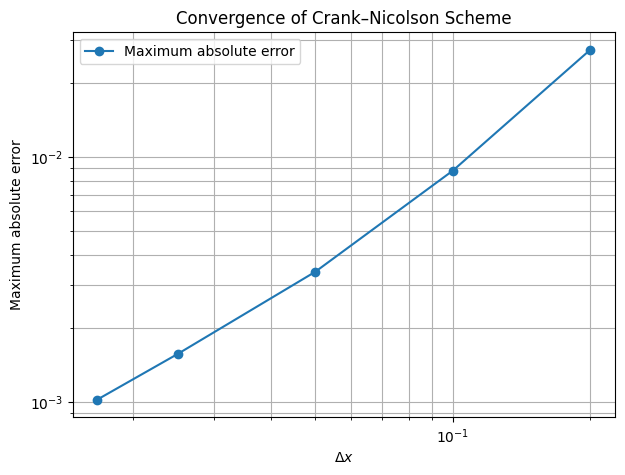

In [525]:
plt.figure(figsize=(7, 5))

plt.loglog(dx_values, errors, 'o-', label='Maximum absolute error')

plt.xlabel(r'$\Delta x$')
plt.ylabel('Maximum absolute error')
plt.title('Convergence of Crank–Nicolson Scheme')
plt.grid(True, which='both')
plt.legend()

plt.show()

### Error Analysis for Example 2

The maximum absolute error was calculated at \(t=0.5\) by comparing the Crank–Nicolson solution with a high-resolution BDF reference solution.

The results showed a clear decrease in error as the spatial grid was refined. For example, the error decreased from

$$
2.742329\times10^{-2}
$$

for \(N_x=10\) to

$$
1.024181\times10^{-3}
$$

for \(N_x=120\). This shows that the Crank–Nicolson solution converges towards the reference solution as the spatial grid is refined.

The observed convergence order was calculated using

$$
p=\frac{\log(E_1/E_2)}
{\log(\Delta x_1/\Delta x_2)}.
$$

The observed orders were \(1.6397\), \(1.3706\), \(1.1134\), and \(1.0584\) for the successive grid refinements. The convergence rate decreases towards approximately first-order behaviour as the grid is refined.

Although the diffusion term is discretised using the Crank–Nicolson method, the nonlinear reaction term is treated explicitly at time level \(n\). In addition, the time step was refined according to approximately

$$
\Delta t\approx0.2\Delta x.
$$

Therefore, the observed convergence rate reflects the combined effect of the spatial and temporal discretisations rather than the formal order of the Crank–Nicolson diffusion discretisation alone.

The error at \(N_x=120\) was approximately

$$
1.024181\times10^{-3},
$$

showing that the numerical solution becomes increasingly close to the high-resolution reference solution as the grid is refined.

Overall, the error analysis confirms that the Crank–Nicolson scheme used for Example 2 produces a convergent numerical solution for the nonlinear reaction-diffusion equation with Neumann boundary conditions. The observed rate approaches first-order behaviour under the chosen \(\Delta t\)-versus-\(\Delta x\) refinement.
